# Model 2 – 01 Data Preparation
**Purpose:** Inventory, clean, de-duplicate and split the anatomical-region dataset (7 fine classes → HAND / LEG / OTHER).
**Inputs:** Research/Model2_data/{Hand,Leg,Other}/<sub-folder>/ ; Research/OTHER_XRAY/Chest_ChestMNIST/
**Outputs:** Research/outputs/model2/ (inventory, manifest_split.csv, cache_224.npz)
**Note:** Folder names = labels, so the notebook can be re-run if the team updates the dataset.

In [1]:
# ===== SETTINGS =====
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
DATA_DIR   = DRIVE_ROOT / 'Model2_data'                         # {Hand,Leg,Other}/<sub-folder>
EXTRA_OTHER_DIRS = [DRIVE_ROOT / 'OTHER_XRAY' / 'Chest_ChestMNIST']  # extra OTHER X-rays
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model2'

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
SEED = 42
IMG_SIZE = 224
SAMPLE_PER_CLASS = 30   # how many images per class to open for the size check

In [2]:
from google.colab import drive
drive.mount('/content/drive')

OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data folder exists:', DATA_DIR.exists())
for d in EXTRA_OTHER_DIRS:
    print(d.name, 'exists:', d.exists())

Mounted at /content/drive
Data folder exists: True
Chest_ChestMNIST exists: True


In [3]:
# QUICK RESUME – only works after Cell 7 (and Cell 16, if you ran it) saved their files
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

full = pd.read_csv(OUT_DIR / 'inventory_full.csv')
ok = full[full['ok']].reset_index(drop=True)
labels = ok['fine_label'].values
print('Inventory loaded:', len(ok), 'images')

cache = OUT_DIR / 'cache_224.npz'
if cache.exists():
    data = np.load(cache, allow_pickle=True)
    X = data['images']
    assert (data['paths'] == ok['path'].values).all(), 'Cache order does not match inventory!'
    print('Cache loaded:', X.shape)
else:
    print('No cache yet – run Cells 15–16.')

Inventory loaded: 3712 images
Cache loaded: (3712, 224, 224)


In [ ]:
import pandas as pd

rows = []

def scan_folder(folder, super_label, fine_label, source):
    """Add every file inside `folder` (including sub-folders) to the list."""
    for p in folder.rglob('*'):
        if p.is_file():
            rows.append({'path': str(p), 'super_label': super_label,
                         'fine_label': fine_label, 'source': source,
                         'ext': p.suffix.lower(), 'filename': p.name})

# Main dataset: the first folder level is HAND/LEG/OTHER, the second level is the fine class
for super_dir in sorted(DATA_DIR.iterdir()):
    if not super_dir.is_dir():
        print('Loose file at top level (ignored):', super_dir.name); continue
    for fine_dir in sorted(super_dir.iterdir()):
        if fine_dir.is_dir():
            scan_folder(fine_dir, super_dir.name.upper(), fine_dir.name, 'Model2_data')
        else:
            print(f'Loose file in {super_dir.name}/ (not in a sub-folder):', fine_dir.name)

# Extra OTHER X-rays (kept with their own fine label and source for now)
for d in EXTRA_OTHER_DIRS:
    scan_folder(d, 'OTHER', d.name, d.name)

inv = pd.DataFrame(rows)
print('Total files found:', len(inv))
print('\nFile types:\n', inv['ext'].value_counts())
print('\nNon-image files:', (~inv['ext'].isin(IMG_EXTS)).sum())
print('\nCounts per class:')
print(inv.groupby(['super_label', 'fine_label']).size().to_string())
print('\nTotals per super class:')
print(inv['super_label'].value_counts().to_string())

Total files found: 3712

File types:
 ext
.jpg    3312
.png     400
Name: count, dtype: int64

Non-image files: 0

Counts per class:
super_label  fine_label                                      
HAND         Elbow to wrist - Radius, Ulna                        619
             Shoulder to elbow - Clavicle, Scapula, Humerus       508
             Wrist and hand - Carpals, Metacarpals, Phalanges    1455
LEG          Foot and ankle - Tarsals, Metatarsals, Phalanges     105
             Hip to knee - Pelvis, Femur, Patella                 239
             Knee to ankle - Tibia, Fibula                        300
OTHER        Chest_ChestMNIST                                     400
             Spine, Chest, Skull and other                         86

Totals per super class:
super_label
HAND     2582
LEG       644
OTHER     486


In [ ]:
from PIL import Image

for fine, grp in inv[inv['ext'].isin(IMG_EXTS)].groupby('fine_label'):
    sample = grp.sample(min(SAMPLE_PER_CLASS, len(grp)), random_state=SEED)
    sizes, modes = [], []
    for p in sample['path']:
        try:
            with Image.open(p) as im:
                sizes.append(im.size); modes.append(im.mode)
        except Exception as e:
            sizes.append('ERROR'); modes.append(str(e)[:30])
    print(f'\n=== {fine} ({len(grp)} files) ===')
    print('Sizes:', pd.Series(sizes).value_counts().head(5).to_dict())
    print('Modes:', pd.Series(modes).value_counts().to_dict())
    print('Example names:', list(grp['filename'].head(3)))


=== Chest_ChestMNIST (400 files) ===
Sizes: {(128, 128): 30}
Modes: {'L': 30}
Example names: ['chest_014592.png', 'chest_003278.png', 'chest_036048.png']

=== Elbow to wrist - Radius, Ulna (619 files) ===
Sizes: {(640, 640): 12, (373, 454): 6, (354, 1024): 1, (416, 416): 1, (666, 666): 1}
Modes: {'RGB': 20, 'L': 10}
Example names: ['fracture_forearm_0459.jpg', 'fracture_forearm_0456.jpg', 'fracture_forearm_0453.jpg']

=== Foot and ankle - Tarsals, Metatarsals, Phalanges (105 files) ===
Sizes: {(640, 640): 10, (373, 454): 9, (1280, 709): 1, (2304, 2880): 1, (442, 442): 1}
Modes: {'RGB': 27, 'L': 3}
Example names: ['fracture_foot-ankle_0037.jpg', 'fracture_foot-ankle_0043.jpg', 'fracture_foot-ankle_0041.jpg']

=== Hip to knee - Pelvis, Femur, Patella (239 files) ===
Sizes: {(640, 640): 17, (373, 454): 8, (458, 600): 1, (2304, 2880): 1, (1598, 920): 1}
Modes: {'RGB': 28, 'L': 2}
Example names: ['fracture_hip-knee_0082.jpg', 'fracture_hip-knee_0083.jpg', 'fracture_hip-knee_0084.jpg']

===

## Step 2 – Full image scan (quality, format, duplicates, annotations)
Opens every image once and records: whether it opens, size, mode (RGB/L/P/16-bit),
EXIF rotation, MD5 (exact duplicate), pHash (near-duplicate) and a colour score
(coloured pixels ≈ drawn arrows/circles/text). Results are saved to
`outputs/model2/inventory_full.csv` so later steps don't re-read Drive.

In [ ]:
!pip install -q imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.5 MB/s eta 0:00:00


In [ ]:
import hashlib, numpy as np, imagehash
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def inspect_image(path):
    """Open one image and collect quality/duplicate information."""
    info = {'ok': False, 'error': '', 'width': None, 'height': None, 'mode': None,
            'file_kb': None, 'md5': None, 'phash': None,
            'color_frac': None, 'exif_rotated': False}
    try:
        data = Path(path).read_bytes()
        info['file_kb'] = round(len(data) / 1024, 1)
        info['md5'] = hashlib.md5(data).hexdigest()          # identical files -> same md5
        with Image.open(path) as im:
            im.load()                                         # forces full decode (catches corrupt files)
            info['width'], info['height'] = im.size
            info['mode'] = im.mode
            info['exif_rotated'] = im.getexif().get(0x0112, 1) != 1
            rgb = im.convert('RGB')
        small = rgb.copy(); small.thumbnail((256, 256))
        a = np.asarray(small).astype(np.int16)
        chroma = a.max(axis=2) - a.min(axis=2)                # 0 for pure gray pixels
        info['color_frac'] = round(float((chroma > 40).mean()), 4)  # share of clearly coloured pixels
        info['phash'] = str(imagehash.phash(rgb.convert('L')))      # near-duplicate fingerprint
        info['ok'] = True
    except Exception as e:
        info['error'] = str(e)[:100]
    return info

with ThreadPoolExecutor(max_workers=16) as ex:                # reads several files at once (faster on Drive)
    results = list(tqdm(ex.map(inspect_image, inv['path']), total=len(inv)))

full = pd.concat([inv.reset_index(drop=True), pd.DataFrame(results)], axis=1)
full.to_csv(OUT_DIR / 'inventory_full.csv', index=False)
print('Saved:', OUT_DIR / 'inventory_full.csv')

  0%|          | 0/3712 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Saved: /content/drive/MyDrive/Research/outputs/model2/inventory_full.csv


### Step 2b – Summary of the scan
Lists unreadable files, image modes, 16-bit and EXIF-rotated counts, size statistics
per class, % of images with colour annotations, and the 10 most colourful images to check visually.

In [ ]:
ok = full[full['ok']].copy()
ok['min_side'] = ok[['width', 'height']].min(axis=1)

print('Unreadable files:', (~full['ok']).sum())
if (~full['ok']).any():
    print(full.loc[~full['ok'], ['fine_label', 'filename', 'error']].to_string())

print('\nImage modes:\n', ok['mode'].value_counts().to_string())
print('16-bit images:', ok['mode'].isin(['I;16', 'I;16B', 'I;16L', 'I']).sum())
print('EXIF-rotated images:', ok['exif_rotated'].sum())

summary = ok.groupby('fine_label').agg(
    n=('path', 'size'),
    median_w=('width', 'median'), median_h=('height', 'median'),
    smallest_side=('min_side', 'min'),
    pct_with_colour=('color_frac', lambda s: round((s > 0.002).mean() * 100, 1)),
)
print('\n', summary.to_string())

print('\nTop 10 most colourful images (likely drawn annotations):')
print(ok.nlargest(10, 'color_frac')[['fine_label', 'filename', 'color_frac']].to_string())

Unreadable files: 0

Image modes:
 mode
RGB     2933
L        722
P         34
RGBA      23
16-bit images: 0
EXIF-rotated images: 1

                                                      n  median_w  median_h  smallest_side  pct_with_colour
fine_label                                                                                                
Chest_ChestMNIST                                   400     128.0     128.0            128              0.0
Elbow to wrist - Radius, Ulna                      619     640.0     640.0            300              2.4
Foot and ankle - Tarsals, Metatarsals, Phalanges   105     640.0     640.0            300              4.8
Hip to knee - Pelvis, Femur, Patella               239     640.0     640.0            331              2.5
Knee to ankle - Tibia, Fibula                      300     640.0     640.0            319              2.3
Shoulder to elbow - Clavicle, Scapula, Humerus     508     512.0     512.0            305              1.4
Spine, Che

## Step 3 – Exact and near-duplicate check
Exact duplicates = same MD5. Near-duplicates = small pHash distance (resized/re-saved copies).
We look at example pairs to choose a distance threshold, then group duplicates so that
all copies of one X-ray go into the same split (train/val/test).

In [ ]:
ok = full[full['ok']].reset_index(drop=True)

dup = ok[ok.duplicated('md5', keep=False)]
groups = dup.groupby('md5')
print('Exact-duplicate files:', len(dup), 'in', groups.ngroups, 'groups')
print('Groups spanning more than one class:', (groups['fine_label'].nunique() > 1).sum())

for md5, g in groups:
    if g['fine_label'].nunique() > 1:          # same file in two different classes = label conflict
        print(g[['fine_label', 'filename']].to_string(index=False)); print('---')

Exact-duplicate files: 0 in 0 groups
Groups spanning more than one class: 0


In [ ]:
# Turn each 64-bit pHash into 64 zeros/ones
bits = np.array([[int(b) for b in bin(int(h, 16))[2:].zfill(64)] for h in ok['phash']], dtype=np.int32)

# Hamming distance = number of differing bits (0 = looks identical, 64 = totally different)
dist = bits @ (1 - bits).T + (1 - bits) @ bits.T

iu = np.triu_indices(len(ok), k=1)              # every pair counted once
d = dist[iu]
labels = ok['fine_label'].values
for t in [0, 2, 4, 6, 8, 10, 12]:
    sel = d <= t
    cross = (labels[iu[0][sel]] != labels[iu[1][sel]]).sum()
    print(f'distance <= {t:2d}: {sel.sum():6d} pairs   (different classes: {cross})')

# Keep close pairs for the visual check
close = d <= 12
pairs = pd.DataFrame({'i': iu[0][close], 'j': iu[1][close], 'd': d[close]})
pairs['cross'] = labels[pairs.i] != labels[pairs.j]

distance <=  0:      7 pairs   (different classes: 0)
distance <=  2:     13 pairs   (different classes: 0)
distance <=  4:     23 pairs   (different classes: 1)
distance <=  6:     43 pairs   (different classes: 2)
distance <=  8:    149 pairs   (different classes: 8)
distance <= 10:    525 pairs   (different classes: 48)
distance <= 12:   1641 pairs   (different classes: 214)


In [ ]:
import matplotlib.pyplot as plt

def show_pairs(dmin, dmax, n=6, cross_only=False):
    """Show up to n random image pairs whose pHash distance is between dmin and dmax."""
    sub = pairs[(pairs.d >= dmin) & (pairs.d <= dmax)]
    if cross_only:
        sub = sub[sub.cross]
    if len(sub) == 0:
        print('No pairs in this range.'); return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(len(sub), 2, figsize=(6, 3 * len(sub)))
    axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, sub.iterrows()):
        for ax, k in zip(row, [r.i, r.j]):
            ax.imshow(Image.open(ok.path[k]).convert('L'), cmap='gray')
            ax.set_title(f'{ok.fine_label[k][:22]}\n{ok.filename[k]}  d={r.d}', fontsize=7)
            ax.axis('off')
    plt.tight_layout(); plt.show()

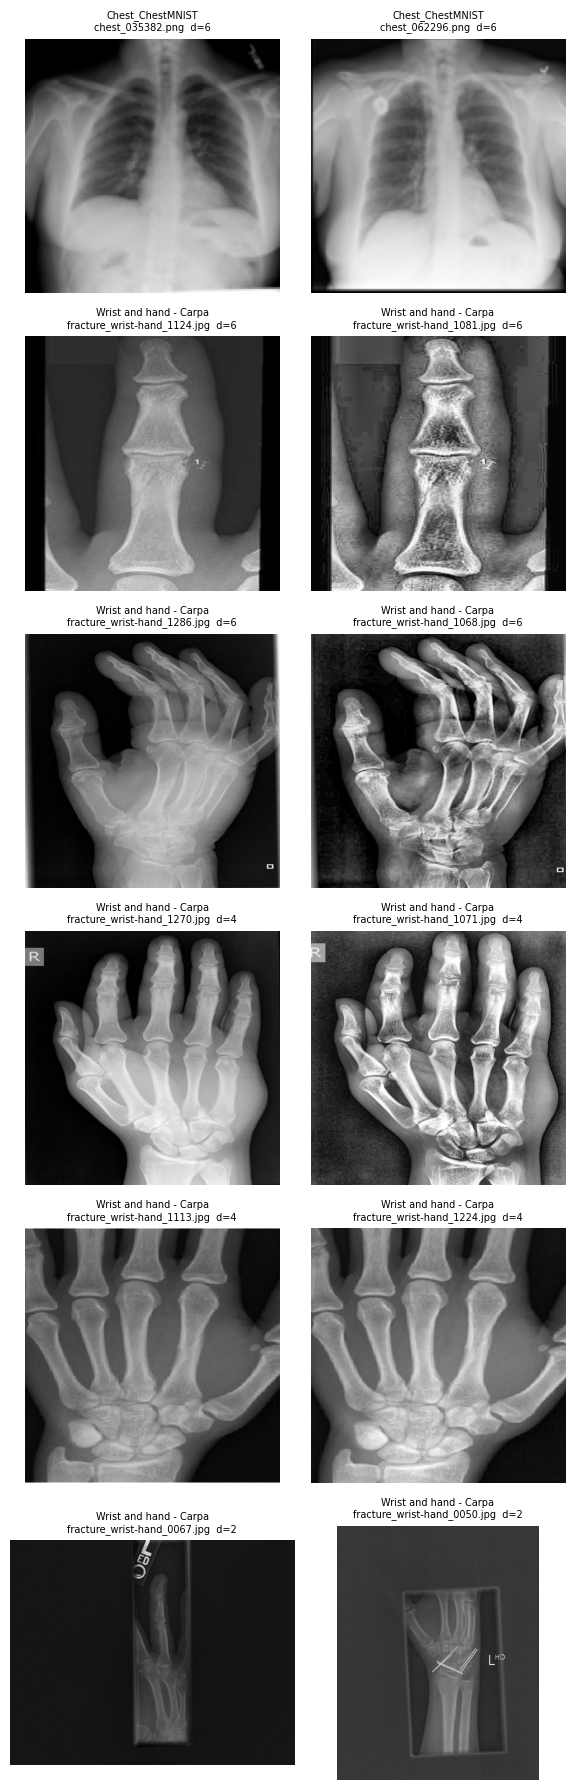

In [ ]:
show_pairs(1, 6)                      # probably the same X-ray?

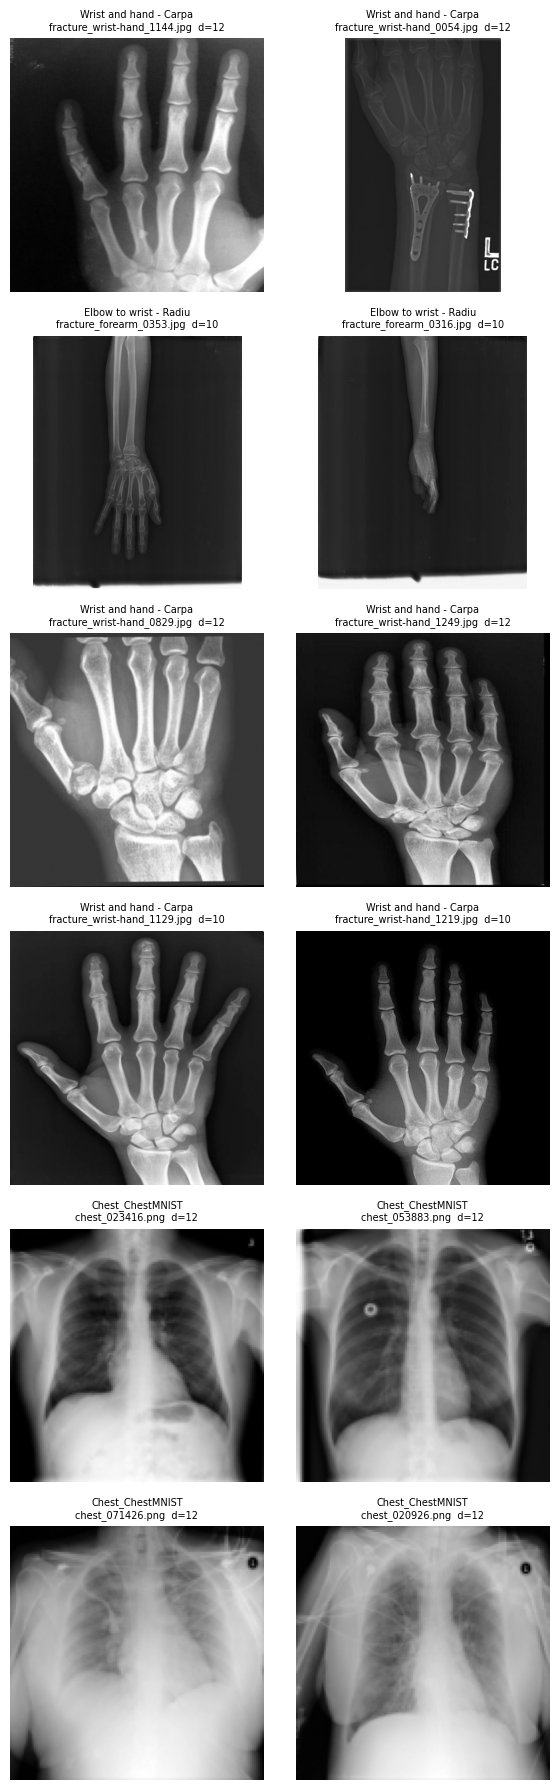

In [ ]:
show_pairs(7, 12)                     # where do "same" pairs stop looking the same?

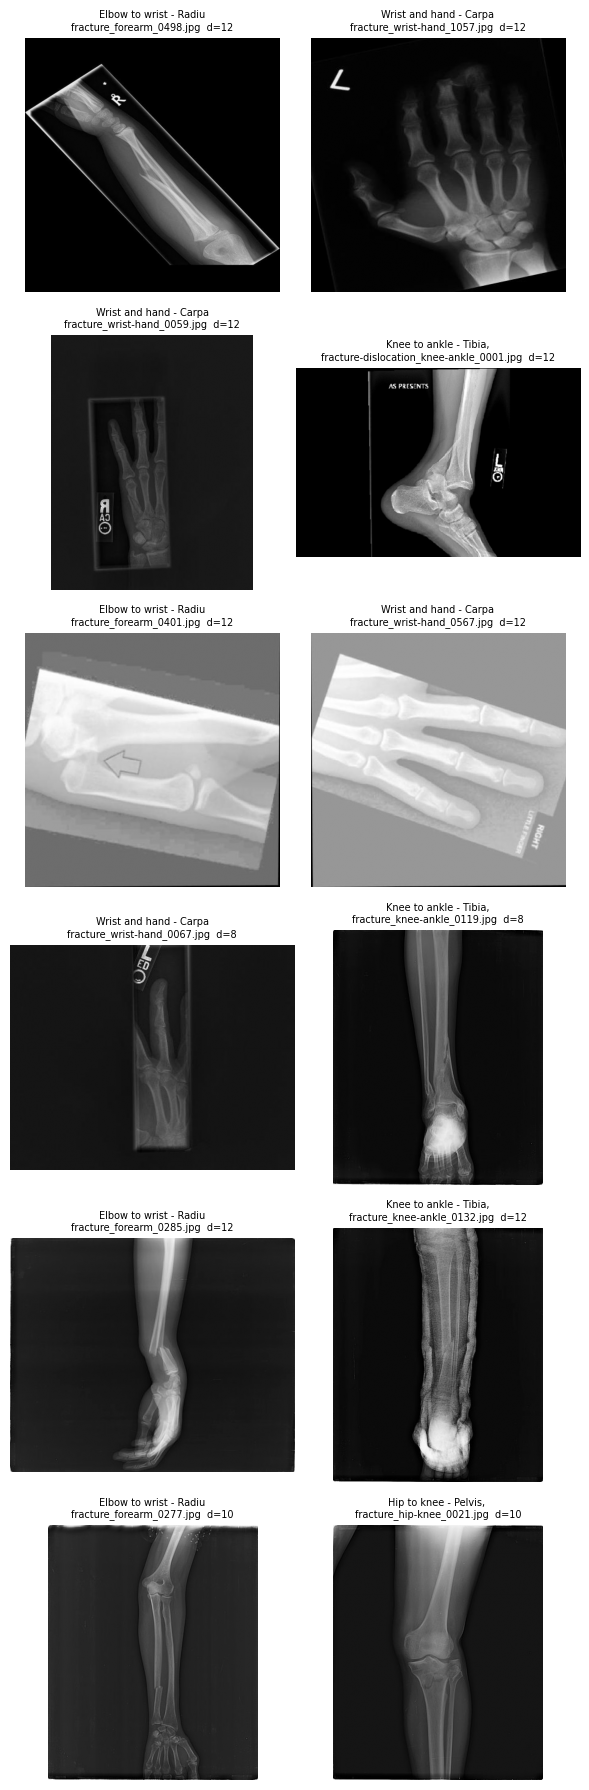

In [ ]:
show_pairs(0, 12, cross_only=True)    # near-identical images with DIFFERENT labels

### Step 3 findings
- Exact duplicates (MD5): 0.
- pHash near-duplicates: visual check showed true copies at d=4–6 (incl. contrast-enhanced copies of the
  same X-ray, e.g. wrist-hand 1270/1071), but also false matches at d=2 (different hands on dark backgrounds).
- Cross-class pairs inspected were all different images → no label conflicts seen.
- Conclusion: pHash alone is unreliable here → contrast-robust, flip/rotation-aware check in Step 5.

## Step 4 – Preprocess all images and cache them (224×224)
Same as Model 1: EXIF orientation fix, 16-bit → 8-bit, transparency → black, grayscale,
pad to square (black, centred), resize to 224×224. Saved as cache_224.npz.

In [ ]:
from PIL import ImageOps

def preprocess(path, size=IMG_SIZE):
    """Load one image and return a 224x224 grayscale uint8 array."""
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)                      # rotate upright if EXIF says so
        if im.mode in ('I;16', 'I;16B', 'I;16L', 'I'):         # 16-bit -> 8-bit (stretch to 0-255)
            a = np.asarray(im, dtype=np.float32)
            a = (a - a.min()) / max(a.max() - a.min(), 1) * 255
            im = Image.fromarray(a.astype(np.uint8))
        if im.mode == 'P':
            im = im.convert('RGBA')
        if im.mode in ('RGBA', 'LA'):                          # transparent areas -> black
            bg = Image.new('RGBA', im.size, (0, 0, 0, 255))
            im = Image.alpha_composite(bg, im.convert('RGBA'))
        im = im.convert('L')                                   # grayscale
        w, h = im.size; s = max(w, h)
        canvas = Image.new('L', (s, s), 0)                     # black square canvas
        canvas.paste(im, ((s - w) // 2, (s - h) // 2))         # centre the image on it
        return np.asarray(canvas.resize((size, size), Image.BILINEAR), dtype=np.uint8)

In [ ]:
with ThreadPoolExecutor(max_workers=16) as ex:
    X = np.stack(list(tqdm(ex.map(preprocess, ok['path']), total=len(ok))))

print('Cached array:', X.shape, X.dtype)          # expect (3712, 224, 224) uint8
np.savez_compressed(OUT_DIR / 'cache_224.npz', images=X, paths=ok['path'].values)
print('Saved:', OUT_DIR / 'cache_224.npz')

  0%|          | 0/3712 [00:00<?, ?it/s]

Cached array: (3712, 224, 224) uint8
Saved: /content/drive/MyDrive/Research/outputs/model2/cache_224.npz


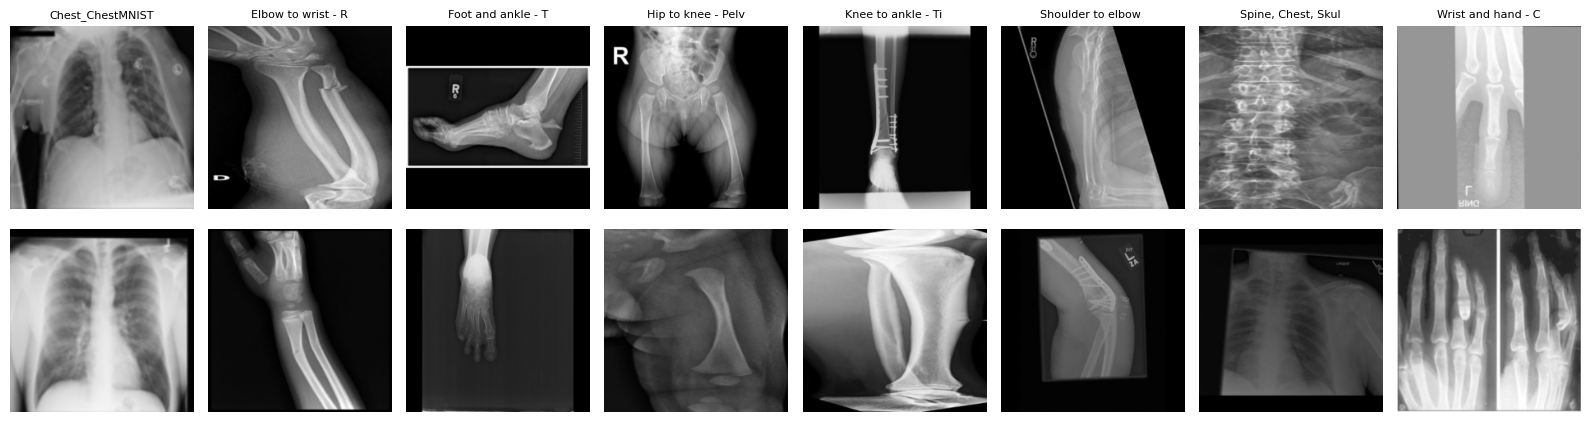

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for c, (fine, grp) in enumerate(ok.groupby('fine_label')):
    for r, idx in enumerate(grp.sample(2, random_state=SEED).index):
        axes[r, c].imshow(X[idx], cmap='gray', vmin=0, vmax=255); axes[r, c].axis('off')
    axes[0, c].set_title(fine[:18], fontsize=8)
plt.tight_layout(); plt.show()

## Step 5 – Near-duplicate check v2 (contrast-robust, flip/rotation-aware)
Each cached image → 32×32 → histogram-equalised → compared with every other image by correlation
(1.0 = identical), also against flipped/rotated versions. Validated on pairs labelled by eye in Step 3.

In [4]:
def to_unit_vectors(a):
    """Flatten, subtract mean, scale to length 1 -> dot product = correlation."""
    a = a.reshape(len(a), -1)
    a = a - a.mean(axis=1, keepdims=True)
    return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)

small = np.stack([np.asarray(ImageOps.equalize(Image.fromarray(x).resize((32, 32), Image.BILINEAR)),
                             dtype=np.float32) for x in X])
base = to_unit_vectors(small)

best = np.full((len(small), len(small)), -1.0, dtype=np.float32)
for k in range(4):                       # 0°, 90°, 180°, 270°
    for flip in (False, True):           # with and without mirror
        t = np.rot90(small, k, axes=(1, 2))
        if flip:
            t = t[:, :, ::-1]
        best = np.maximum(best, base @ to_unit_vectors(np.ascontiguousarray(t)).T)
np.fill_diagonal(best, -1)               # ignore each image compared with itself

iu = np.triu_indices(len(ok), k=1)
s = best[iu]
for t in [0.98, 0.95, 0.92, 0.90, 0.85, 0.80]:
    sel = s >= t
    cross = (labels[iu[0][sel]] != labels[iu[1][sel]]).sum()
    print(f'similarity >= {t:.2f}: {sel.sum():6d} pairs   (different classes: {cross})')

keep = s >= 0.80
sim_pairs = pd.DataFrame({'i': iu[0][keep], 'j': iu[1][keep], 's': s[keep].round(3)})
sim_pairs['cross'] = labels[sim_pairs.i] != labels[sim_pairs.j]

similarity >= 0.98:     72 pairs   (different classes: 34)
similarity >= 0.95:   1092 pairs   (different classes: 584)
similarity >= 0.92:   6989 pairs   (different classes: 3483)
similarity >= 0.90:  16889 pairs   (different classes: 8309)
similarity >= 0.85:  81098 pairs   (different classes: 41233)
similarity >= 0.80: 237042 pairs   (different classes: 129334)


In [5]:
def sim_of(f1, f2):
    i = ok.index[ok.filename == f1][0]; j = ok.index[ok.filename == f2][0]
    return round(float(best[i, j]), 3)

checks = [('fracture_wrist-hand_1124.jpg', 'fracture_wrist-hand_1081.jpg', 'SAME'),
          ('fracture_wrist-hand_1286.jpg', 'fracture_wrist-hand_1068.jpg', 'SAME'),
          ('fracture_wrist-hand_1270.jpg', 'fracture_wrist-hand_1071.jpg', 'SAME'),
          ('fracture_wrist-hand_1113.jpg', 'fracture_wrist-hand_1224.jpg', 'SAME'),
          ('fracture_wrist-hand_0067.jpg', 'fracture_wrist-hand_0050.jpg', 'DIFFERENT'),
          ('chest_035382.png', 'chest_062296.png', 'DIFFERENT')]
for a, b, truth in checks:
    print(f'{truth:9s}  {sim_of(a, b):.3f}   {a} vs {b}')

SAME       0.916   fracture_wrist-hand_1124.jpg vs fracture_wrist-hand_1081.jpg
SAME       0.897   fracture_wrist-hand_1286.jpg vs fracture_wrist-hand_1068.jpg
SAME       0.851   fracture_wrist-hand_1270.jpg vs fracture_wrist-hand_1071.jpg
SAME       0.993   fracture_wrist-hand_1113.jpg vs fracture_wrist-hand_1224.jpg
DIFFERENT  0.558   fracture_wrist-hand_0067.jpg vs fracture_wrist-hand_0050.jpg
DIFFERENT  0.844   chest_035382.png vs chest_062296.png


In [6]:
def show_sim(lo, hi, n=6, cross_only=False):
    sub = sim_pairs[(sim_pairs.s >= lo) & (sim_pairs.s <= hi)]
    if cross_only:
        sub = sub[sub.cross]
    if len(sub) == 0:
        print('No pairs in this range.'); return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(len(sub), 2, figsize=(6, 3 * len(sub)))
    axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, sub.iterrows()):
        for ax, k in zip(row, [r.i, r.j]):
            ax.imshow(X[k], cmap='gray'); ax.axis('off')
            ax.set_title(f'{ok.fine_label[k][:22]}\n{ok.filename[k]}  s={r.s}', fontsize=7)
    plt.tight_layout(); plt.show()

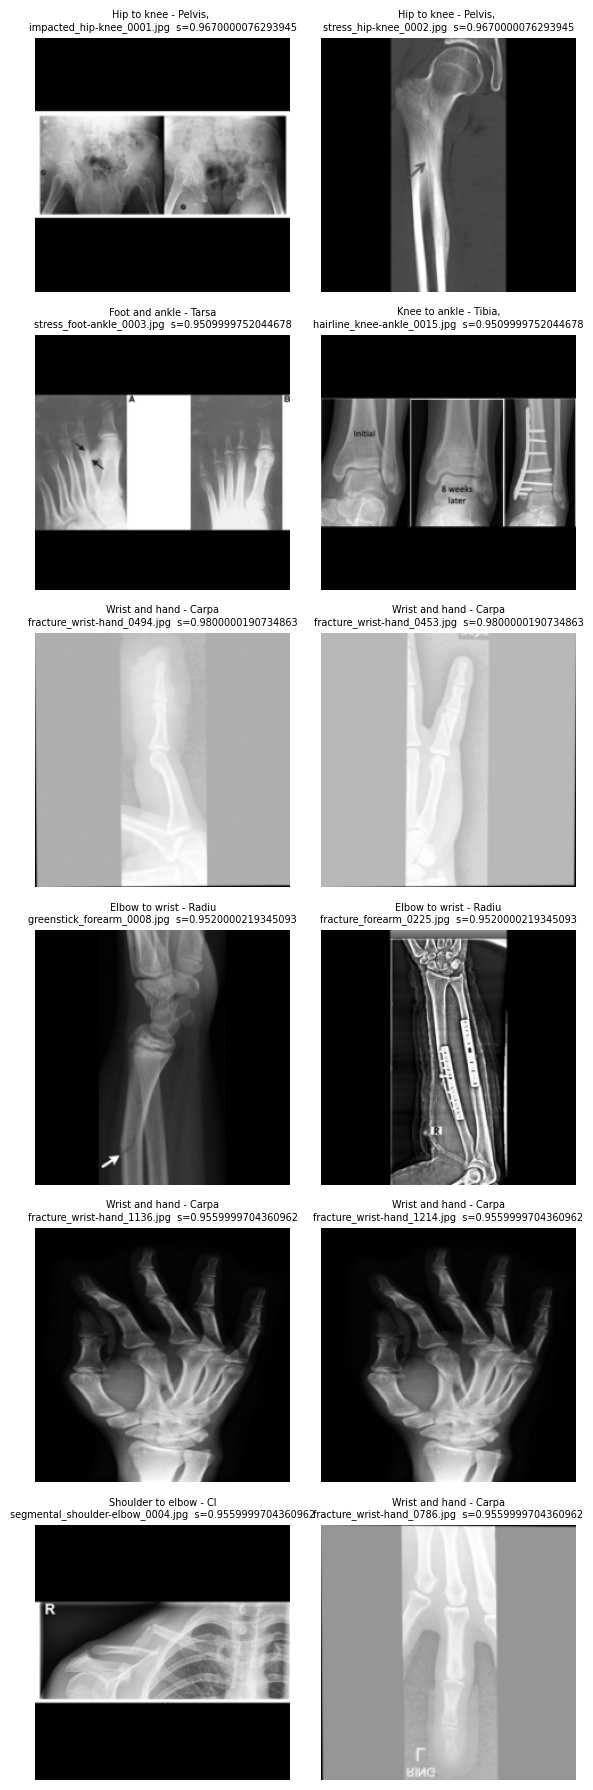

In [7]:
show_sim(0.95, 1.00)

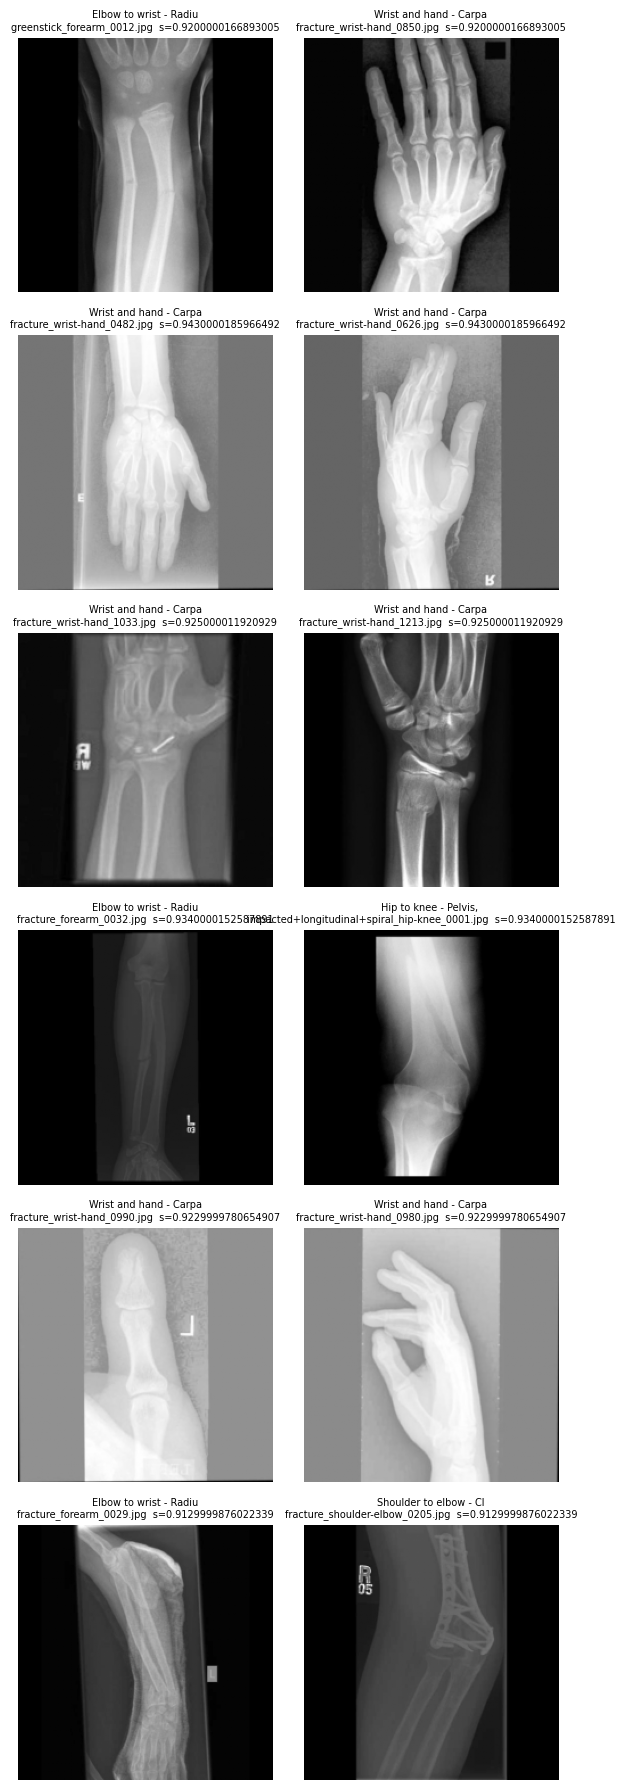

In [8]:
show_sim(0.90, 0.95)

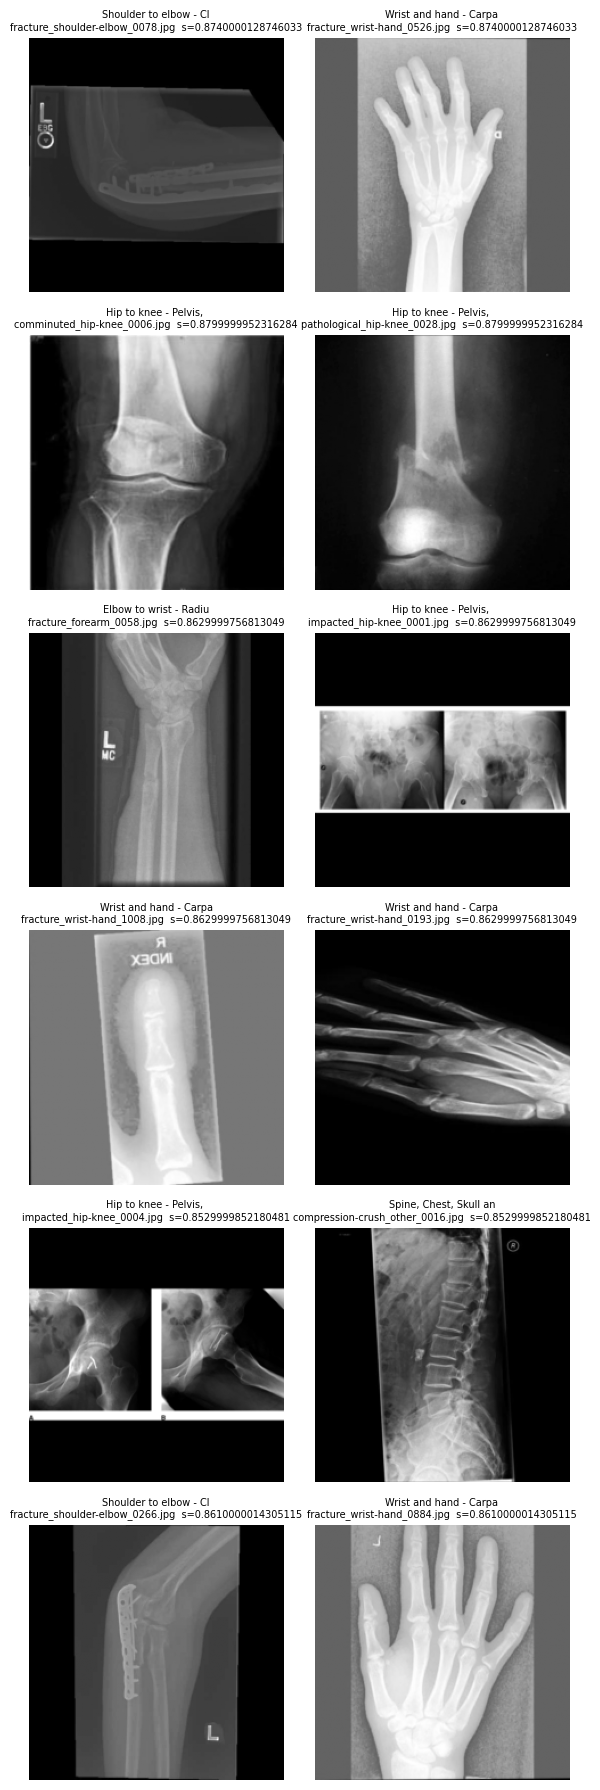

In [9]:
show_sim(0.85, 0.90)

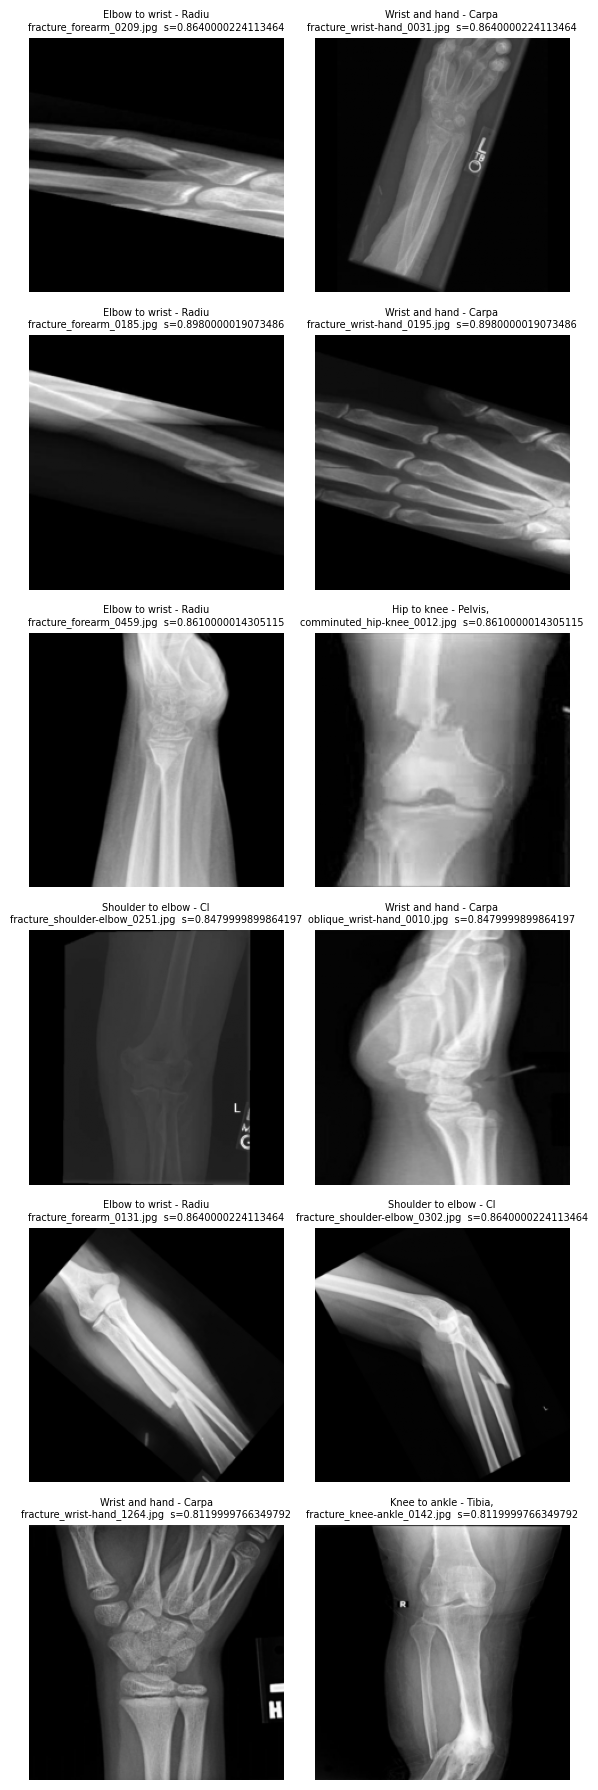

In [10]:
show_sim(0.80, 1.00, cross_only=True)

### Step 5 findings
Correlation of 32×32 equalised images does NOT separate copies from different images:
true copies scored 0.85–0.99, different images up to 0.98 (e.g. wrist-hand 0494/0453).
Cause: at low resolution the global layout (padding, background, cassette frame) dominates.
Cross-class pairs inspected were all different X-rays → still no label conflicts.
→ Step 6 uses a two-stage approach instead.

## Step 6 – Near-duplicate check v3: CNN shortlist + ORB/RANSAC verification
1. MobileNetV3 (ImageNet) features → each image's 10 most similar images (incl. flipped) = candidate pairs.
2. Each candidate pair is verified with ORB keypoints + RANSAC: count of geometrically consistent matches
   ("inliers"). Copies give many inliers; different images give few. Validated on pairs labelled by eye.

In [12]:
import torch
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights

device = 'cuda' if torch.cuda.is_available() else 'cpu'
net = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
net.classifier = torch.nn.Identity()          # remove the last layer -> 960 numbers per image
net.eval().to(device)
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
std  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

def embed(arr):
    """224x224 grayscale images -> one feature vector (length 1) per image."""
    out = []
    with torch.no_grad():
        for i in range(0, len(arr), 128):
            x = torch.from_numpy(arr[i:i+128]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
            f = net((x - mean) / std)
            out.append(torch.nn.functional.normalize(f, dim=1).cpu())
    return torch.cat(out).numpy()

E      = embed(X)
E_flip = embed(np.ascontiguousarray(X[:, :, ::-1]))   # mirrored images

S = np.maximum(E @ E.T, E @ E_flip.T)    # similarity, also checking the mirrored version
np.fill_diagonal(S, -1)

K = 10
nn_idx = np.argsort(-S, axis=1)[:, :K]   # 10 most similar images for each image
cand = sorted({(min(i, j), max(i, j)) for i in range(len(S)) for j in nn_idx[i]})
print('Candidate pairs:', len(cand))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 128MB/s] 


Candidate pairs: 29158


In [13]:
import cv2

orb   = cv2.ORB_create(nfeatures=1000)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))   # evens out contrast differences
bf    = cv2.BFMatcher(cv2.NORM_HAMMING)

def orb_feats(img):
    big = cv2.resize(clahe.apply(img), (448, 448))             # upscale -> more keypoints
    return orb.detectAndCompute(big, None)

feats      = [orb_feats(x) for x in tqdm(X)]
feats_flip = [orb_feats(np.ascontiguousarray(x[:, ::-1])) for x in tqdm(X)]

def inliers(fa, fb):
    """Number of keypoint matches that agree on one rotation/scale/shift."""
    (ka, da), (kb, db) = fa, fb
    if da is None or db is None or len(ka) < 10 or len(kb) < 10:
        return 0
    good = [p[0] for p in bf.knnMatch(da, db, k=2)
            if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < 8:
        return 0
    pa = np.float32([ka[m.queryIdx].pt for m in good])
    pb = np.float32([kb[m.trainIdx].pt for m in good])
    _, mask = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC, ransacReprojThreshold=5.0)
    return 0 if mask is None else int(mask.sum())

def verify(i, j):
    return max(inliers(feats[i], feats[j]), inliers(feats[i], feats_flip[j]))

  0%|          | 0/3712 [00:00<?, ?it/s]

  0%|          | 0/3712 [00:00<?, ?it/s]

In [14]:
cand_set = set(cand)
checks = [('fracture_wrist-hand_1124.jpg', 'fracture_wrist-hand_1081.jpg', 'SAME'),
          ('fracture_wrist-hand_1286.jpg', 'fracture_wrist-hand_1068.jpg', 'SAME'),
          ('fracture_wrist-hand_1270.jpg', 'fracture_wrist-hand_1071.jpg', 'SAME'),
          ('fracture_wrist-hand_1113.jpg', 'fracture_wrist-hand_1224.jpg', 'SAME'),
          ('fracture_wrist-hand_1136.jpg', 'fracture_wrist-hand_1214.jpg', 'SAME'),
          ('fracture_wrist-hand_0067.jpg', 'fracture_wrist-hand_0050.jpg', 'DIFFERENT'),
          ('fracture_wrist-hand_0494.jpg', 'fracture_wrist-hand_0453.jpg', 'DIFFERENT'),
          ('impacted_hip-knee_0001.jpg',   'stress_hip-knee_0002.jpg',     'DIFFERENT'),
          ('chest_035382.png',             'chest_062296.png',             'DIFFERENT')]
print('truth      cnn_sim  shortlisted  inliers')
for a, b, truth in checks:
    i = ok.index[ok.filename == a][0]; j = ok.index[ok.filename == b][0]
    print(f'{truth:9s}  {S[i, j]:.3f}    {str((min(i,j), max(i,j)) in cand_set):5s}       {verify(i, j):4d}   {a} vs {b}')

truth      cnn_sim  shortlisted  inliers
SAME       0.804    True          17   fracture_wrist-hand_1124.jpg vs fracture_wrist-hand_1081.jpg
SAME       0.766    True          68   fracture_wrist-hand_1286.jpg vs fracture_wrist-hand_1068.jpg
SAME       0.819    True          85   fracture_wrist-hand_1270.jpg vs fracture_wrist-hand_1071.jpg
SAME       0.970    True         348   fracture_wrist-hand_1113.jpg vs fracture_wrist-hand_1224.jpg
SAME       0.986    True         354   fracture_wrist-hand_1136.jpg vs fracture_wrist-hand_1214.jpg
DIFFERENT  0.423    False          0   fracture_wrist-hand_0067.jpg vs fracture_wrist-hand_0050.jpg
DIFFERENT  0.667    False          0   fracture_wrist-hand_0494.jpg vs fracture_wrist-hand_0453.jpg
DIFFERENT  0.362    False          3   impacted_hip-knee_0001.jpg vs stress_hip-knee_0002.jpg
DIFFERENT  0.803    True           0   chest_035382.png vs chest_062296.png


In [15]:
ver = pd.DataFrame(cand, columns=['i', 'j'])
ver['inliers'] = [verify(i, j) for i, j in tqdm(cand)]
ver['cnn_sim'] = S[ver.i, ver.j].round(3)
ver['cross']   = labels[ver.i] != labels[ver.j]

for t in [8, 12, 15, 20, 30, 50, 100]:
    sel = ver.inliers >= t
    print(f'inliers >= {t:3d}: {sel.sum():5d} pairs   (different classes: {(sel & ver.cross).sum()})')

  0%|          | 0/29158 [00:00<?, ?it/s]

inliers >=   8:  3027 pairs   (different classes: 418)
inliers >=  12:  1246 pairs   (different classes: 163)
inliers >=  15:   741 pairs   (different classes: 106)
inliers >=  20:   402 pairs   (different classes: 58)
inliers >=  30:   227 pairs   (different classes: 34)
inliers >=  50:   145 pairs   (different classes: 15)
inliers >= 100:   101 pairs   (different classes: 7)


In [16]:
def show_ver(lo, hi, n=6, cross_only=False):
    sub = ver[(ver.inliers >= lo) & (ver.inliers <= hi)]
    if cross_only:
        sub = sub[sub.cross]
    if len(sub) == 0:
        print('No pairs in this range.'); return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(len(sub), 2, figsize=(6, 3 * len(sub)))
    axes = np.atleast_2d(axes)
    for row, (_, r) in zip(axes, sub.iterrows()):
        for ax, k in zip(row, [r.i, r.j]):
            ax.imshow(X[k], cmap='gray'); ax.axis('off')
            ax.set_title(f'{ok.fine_label[k][:22]}\n{ok.filename[k]}  inl={r.inliers}', fontsize=7)
    plt.tight_layout(); plt.show()

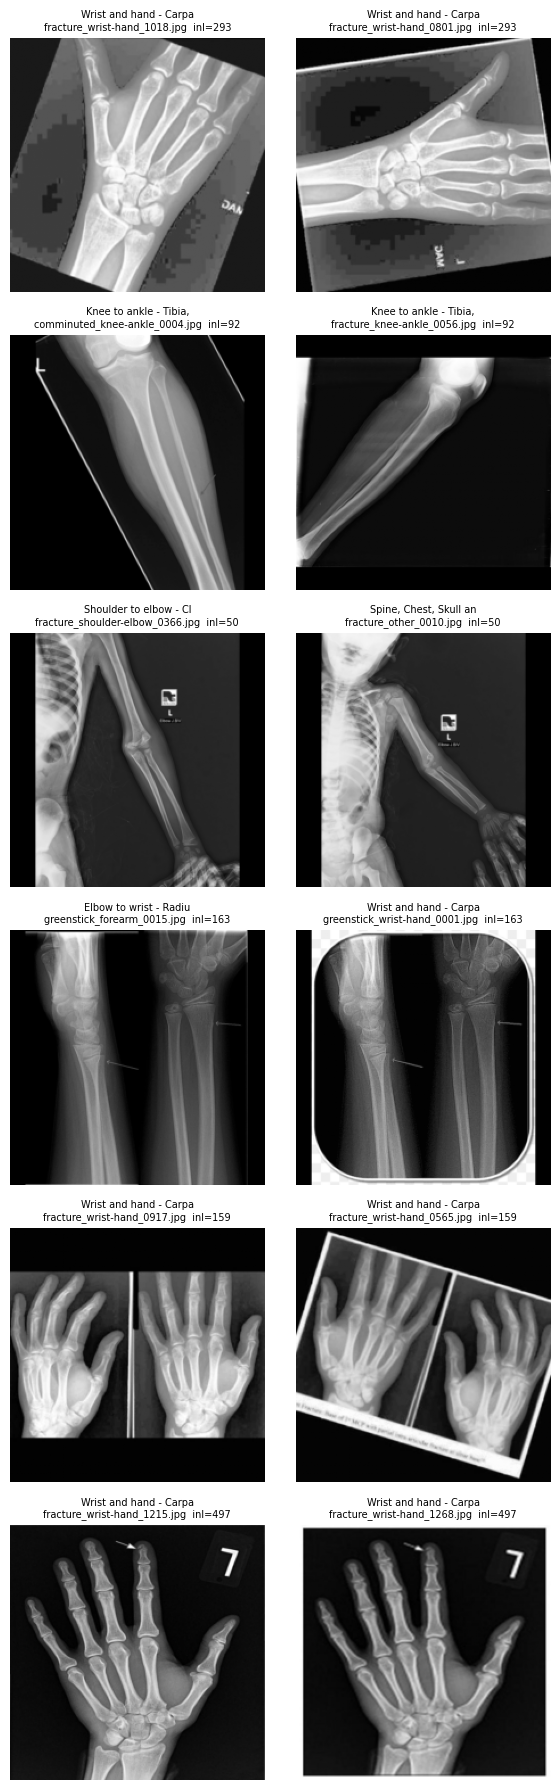

In [17]:
show_ver(50, 10000)

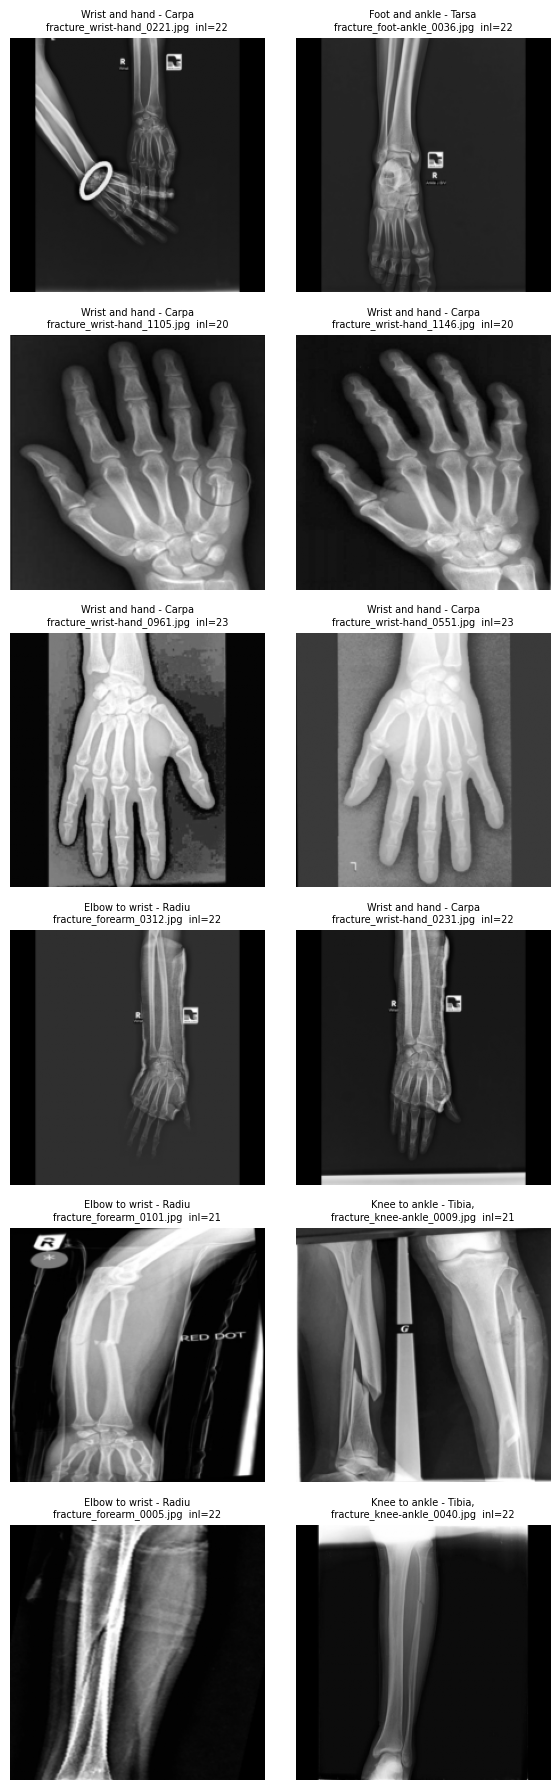

In [18]:
show_ver(20, 49)

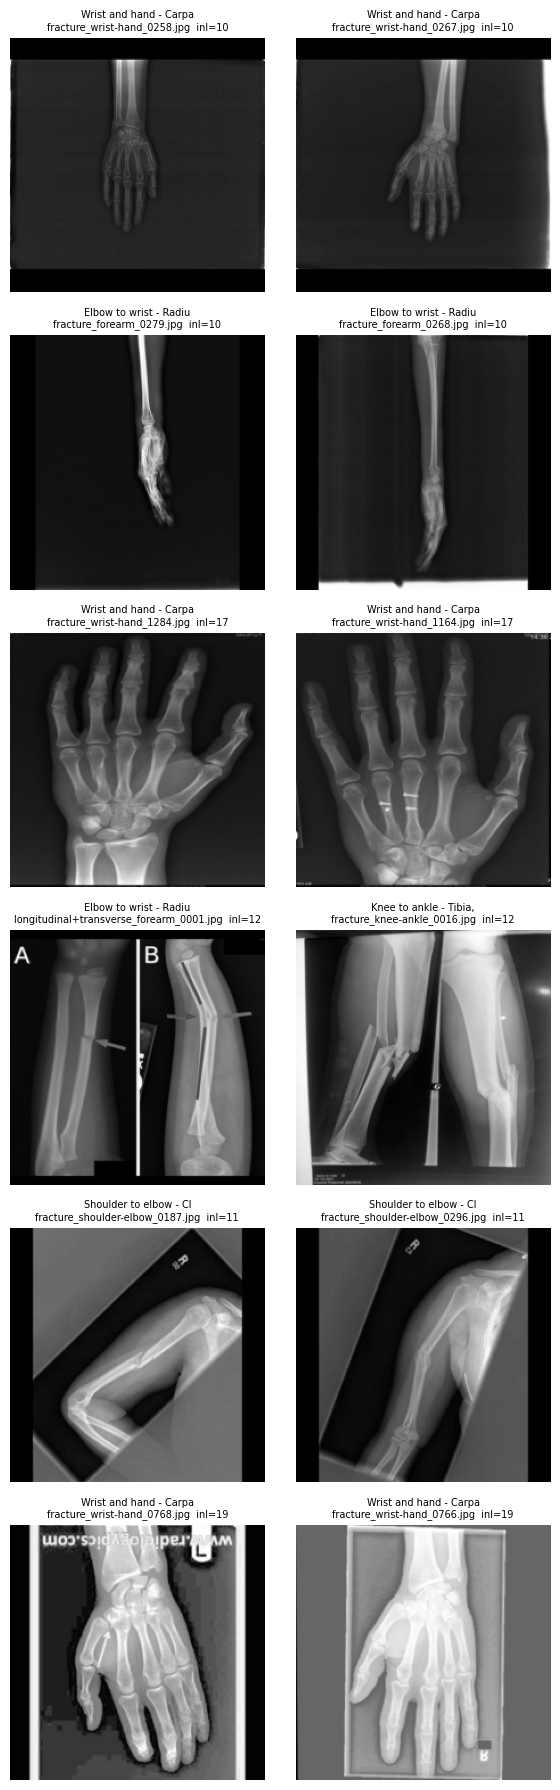

In [19]:
show_ver(10, 19)

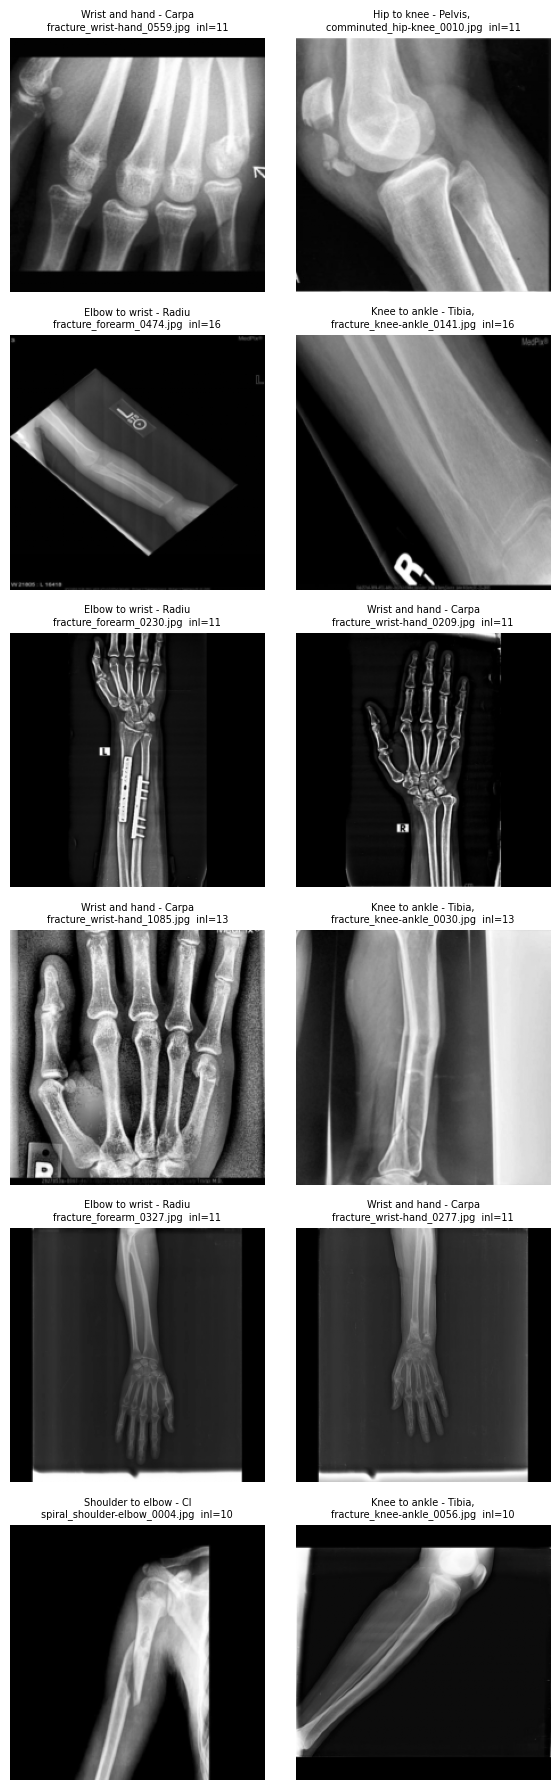

In [20]:
show_ver(10, 10000, cross_only=True)

### Step 6 findings
- Validation: true copies 17–354 inliers; different images 0–3 → ORB/RANSAC separates them.
- Visual check: ≥50 inliers = always the same X-ray. 20–49 = same-class pairs mostly copies; cross-class pairs
  mostly false matches caused by shared R/L markers/logos. <20 = mostly different images.
- Found the SAME X-ray in two classes (e.g. forearm_0015 = wrist-hand_0001; shoulder-elbow_0366 = other_0010)
  → label ambiguity, reviewed below.
- Rule: same class ≥15 inliers, different classes ≥50 inliers → "same X-ray". A low threshold is the safe side:
  wrongly grouping two images costs little; missing a copy causes train/test leakage.

## Step 7 – Build duplicate groups
Linked images are joined into groups (connected components). Every group will later go entirely into one split.

In [21]:
ver['file_i'] = ok.filename.values[ver.i]
ver['file_j'] = ok.filename.values[ver.j]
ver.to_csv(OUT_DIR / 'duplicate_pairs.csv', index=False)
print('Saved:', OUT_DIR / 'duplicate_pairs.csv')

Saved: /content/drive/MyDrive/Research/outputs/model2/duplicate_pairs.csv


In [22]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

T_SAME, T_CROSS = 15, 50
link = ver[((~ver.cross) & (ver.inliers >= T_SAME)) | (ver.cross & (ver.inliers >= T_CROSS))]

n = len(ok)
A = coo_matrix((np.ones(len(link)), (link.i, link.j)), shape=(n, n))
_, group_id = connected_components(A, directed=False)   # images linked directly or via a chain share one id
ok['dup_group'] = group_id

sizes = ok['dup_group'].value_counts()
ok['group_size'] = ok['dup_group'].map(sizes)
print('Pairs used for linking:', len(link))
print('Images that have at least one copy:', (ok.group_size > 1).sum(), 'of', n)
print('Number of duplicate groups:', (sizes > 1).sum())
print('\nGroup size -> how many groups:')
print(sizes[sizes > 1].value_counts().sort_index().to_string())

print('\nLargest 3 groups:')
for g in sizes.index[:3]:
    print(f'  group {g} ({sizes[g]} images):', ok.loc[ok.dup_group == g, 'fine_label'].value_counts().to_dict())

mixed = ok[ok.group_size > 1].groupby('dup_group')['fine_label'].nunique()
print('\nGroups containing more than one class:', (mixed > 1).sum())

Pairs used for linking: 650
Images that have at least one copy: 726 of 3712
Number of duplicate groups: 219

Group size -> how many groups:
count
2      159
3       33
4       13
5        7
6        1
7        2
9        2
18       1
166      1

Largest 3 groups:
  group 1053 (166 images): {'Wrist and hand - Carpals, Metacarpals, Phalanges': 166}
  group 1720 (18 images): {'Wrist and hand - Carpals, Metacarpals, Phalanges': 18}
  group 2519 (9 images): {'Knee to ankle - Tibia, Fibula': 9}

Groups containing more than one class: 13


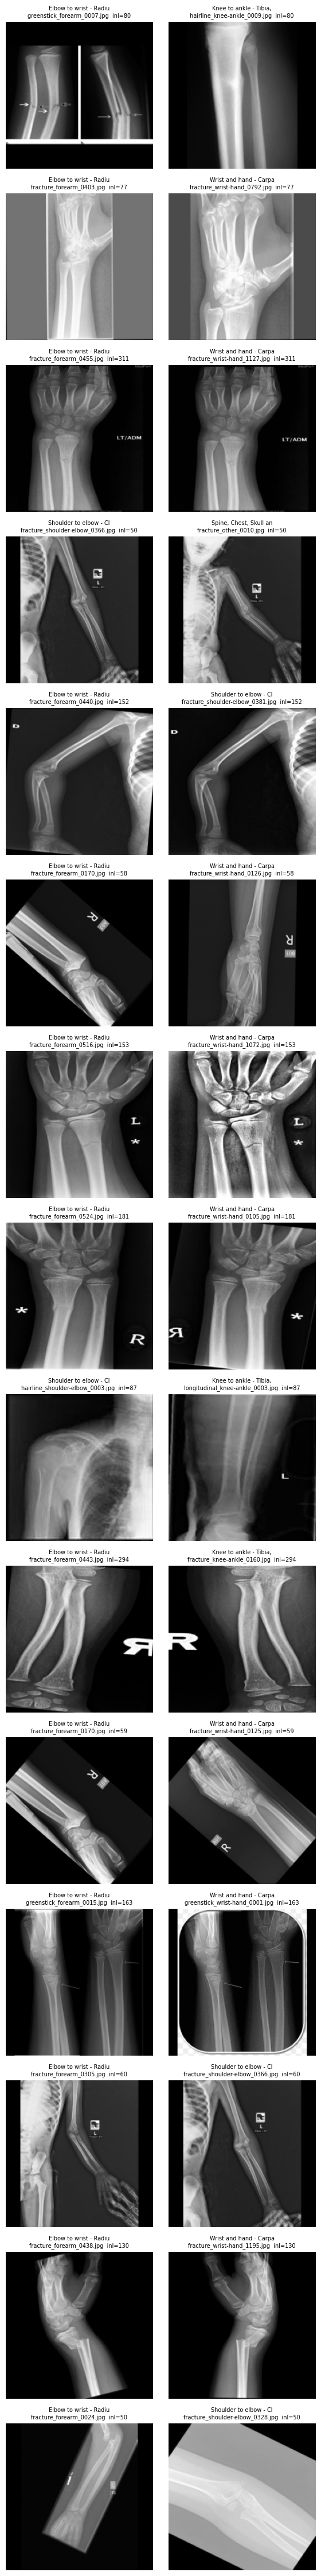

In [23]:
show_ver(50, 10000, n=20, cross_only=True)

### Cross-class review (inliers ≥ 50)
12 of 15 pairs = same X-ray, mostly Elbow-to-wrist vs Wrist-and-hand (fuzzy boundary).
2 false matches at 80/87 inliers (forearm_0007/knee-ankle_0009, shoulder-elbow_0003/knee-ankle_0003) → removed.
1 unsure (forearm_0024/shoulder-elbow_0328) → kept linked (safe side).
forearm_0443 = knee-ankle_0160 (HAND vs LEG) → likely mislabel, reported to team.
Decision: images whose copies carry different labels are excluded (saved in label_conflicts.csv).

In [24]:
FALSE_PAIRS = {frozenset(['greenstick_forearm_0007.jpg', 'hairline_knee-ankle_0009.jpg']),
               frozenset(['hairline_shoulder-elbow_0003.jpg', 'longitudinal_knee-ankle_0003.jpg'])}

is_false = ver.apply(lambda r: frozenset([r.file_i, r.file_j]) in FALSE_PAIRS, axis=1)
link = ver[~is_false & (((~ver.cross) & (ver.inliers >= T_SAME)) |
                        (ver.cross & (ver.inliers >= T_CROSS)))]

A = coo_matrix((np.ones(len(link)), (link.i, link.j)), shape=(n, n))
_, group_id = connected_components(A, directed=False)
ok['dup_group'] = group_id
sizes = ok['dup_group'].value_counts()
ok['group_size'] = ok['dup_group'].map(sizes)

# a group whose images have more than one fine label = label conflict
ok['label_conflict'] = ok.groupby('dup_group')['fine_label'].transform('nunique') > 1
conf = ok[ok.label_conflict].sort_values(['dup_group', 'fine_label'])
conf[['dup_group', 'fine_label', 'filename', 'path']].to_csv(OUT_DIR / 'label_conflicts.csv', index=False)

print('Images in label-conflict groups:', len(conf), 'in', conf.dup_group.nunique(), 'groups')
print(conf[['dup_group', 'fine_label', 'filename']].to_string(index=False))
print('\nLargest groups (size):', sizes.head(3).to_dict())

Images in label-conflict groups: 30 in 11 groups
 dup_group                                       fine_label                         filename
        14                    Elbow to wrist - Radius, Ulna        fracture_forearm_0455.jpg
        14 Wrist and hand - Carpals, Metacarpals, Phalanges     fracture_wrist-hand_1127.jpg
        70                    Elbow to wrist - Radius, Ulna        fracture_forearm_0524.jpg
        70 Wrist and hand - Carpals, Metacarpals, Phalanges     fracture_wrist-hand_0105.jpg
        81                    Elbow to wrist - Radius, Ulna        fracture_forearm_0516.jpg
        81 Wrist and hand - Carpals, Metacarpals, Phalanges     fracture_wrist-hand_1072.jpg
       105                    Elbow to wrist - Radius, Ulna        fracture_forearm_0438.jpg
       105 Wrist and hand - Carpals, Metacarpals, Phalanges     fracture_wrist-hand_1195.jpg
       107                    Elbow to wrist - Radius, Ulna        fracture_forearm_0443.jpg
       107           

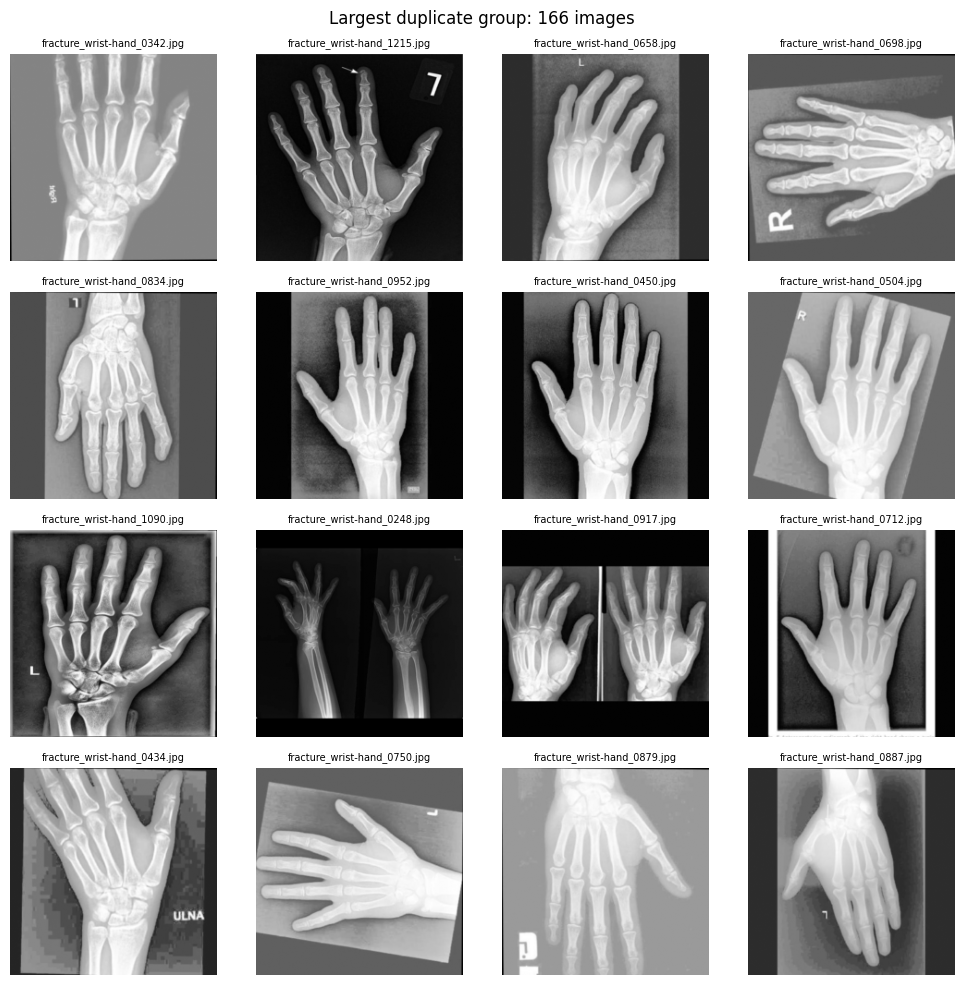

In [25]:
big = sizes.index[0]
idx = ok.index[ok.dup_group == big]
sample = np.random.RandomState(SEED).choice(idx, min(16, len(idx)), replace=False)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, k in zip(axes.flat, sample):
    ax.imshow(X[k], cmap='gray'); ax.set_title(ok.filename[k], fontsize=7); ax.axis('off')
plt.suptitle(f'Largest duplicate group: {len(idx)} images'); plt.tight_layout(); plt.show()

### Largest group check
The 166-image group contains clearly different hands → a chain of weak links (similar-looking PA hand views),
not real copies. Groups > 20 images are rebuilt using only strong links (≥ 50 inliers).

## Step 8 – Final dataset and group-aware stratified split (70/15/15)
- Exclude the 30 label-conflict images (label_conflicts.csv).
- Training label: 7 classes (6 limb classes + OTHER = Spine/Chest/Skull + ChestMNIST); `source` column kept.
- Split with StratifiedGroupKFold: class balance kept, each duplicate group stays in ONE split.
- Output: outputs/model2/manifest_split.csv

In [26]:
T_STRONG = 50
for g in sizes[sizes > 20].index:
    members = np.where(ok.dup_group.values == g)[0]
    pos = {k: p for p, k in enumerate(members)}
    sub = link[link.i.isin(members) & link.j.isin(members) & (link.inliers >= T_STRONG)]
    A2 = coo_matrix((np.ones(len(sub)), (sub.i.map(pos), sub.j.map(pos))), shape=(len(members),) * 2)
    _, sub_id = connected_components(A2, directed=False)
    ok.loc[members, 'dup_group'] = ok.dup_group.max() + 1 + sub_id   # give the pieces new group ids

sizes = ok['dup_group'].value_counts()
print('Largest groups now:', sizes.head(5).to_dict())
print('Images that have at least one copy:', (ok['dup_group'].map(sizes) > 1).sum())

Largest groups now: {1720: 18, 1719: 9, 2520: 9, 118: 7, 401: 7}
Images that have at least one copy: 592


In [27]:
OTHER_FINE = {'Spine, Chest, Skull and other', 'Chest_ChestMNIST'}
ok['label'] = np.where(ok.fine_label.isin(OTHER_FINE), 'OTHER', ok.fine_label)   # 7 training classes
ok['has_colour_annotation'] = ok.color_frac > 0.002
ok['cache_idx'] = np.arange(len(ok))           # row number in cache_224.npz

data = ok[~ok.label_conflict].copy()
print('Images kept:', len(data), ' excluded:', ok.label_conflict.sum())
print(data['label'].value_counts().to_string())

Images kept: 3682  excluded: 30
label
Wrist and hand - Carpals, Metacarpals, Phalanges    1445
Elbow to wrist - Radius, Ulna                        607
Shoulder to elbow - Clavicle, Scapula, Humerus       503
OTHER                                                484
Knee to ankle - Tibia, Fibula                        299
Hip to knee - Pelvis, Femur, Patella                 239
Foot and ankle - Tarsals, Metatarsals, Phalanges     105


In [28]:
from sklearn.model_selection import StratifiedGroupKFold

def group_split(df, n_splits, seed):
    """Take 1/n_splits of df as a hold-out set, keeping classes balanced and groups together."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest, hold = next(sgkf.split(df, df['label'], groups=df['dup_group']))
    return df.iloc[rest], df.iloc[hold]

trainval, test = group_split(data, 7, SEED)    # 1/7 ≈ 15% test
train, val     = group_split(trainval, 6, SEED)  # 1/6 of the rest ≈ 15% val

data['split'] = 'train'
data.loc[val.index, 'split'] = 'val'
data.loc[test.index, 'split'] = 'test'

In [29]:
print(pd.crosstab(data['label'], data['split'], margins=True)[['train', 'val', 'test', 'All']])
print('\nSplit %:', (data['split'].value_counts(normalize=True) * 100).round(1).to_dict())
print('Groups spread over more than one split:', (data.groupby('dup_group')['split'].nunique() > 1).sum())

cols = ['path', 'filename', 'super_label', 'fine_label', 'label', 'source', 'split',
        'dup_group', 'has_colour_annotation', 'color_frac', 'width', 'height', 'mode', 'cache_idx']
data[cols].to_csv(OUT_DIR / 'manifest_split.csv', index=False)
print('\nSaved:', OUT_DIR / 'manifest_split.csv')

split                                             train  val  test   All
label                                                                   
Elbow to wrist - Radius, Ulna                       442   82    83   607
Foot and ankle - Tarsals, Metatarsals, Phalanges     78   15    12   105
Hip to knee - Pelvis, Femur, Patella                174   30    35   239
Knee to ankle - Tibia, Fibula                       208   51    40   299
OTHER                                               345   69    70   484
Shoulder to elbow - Clavicle, Scapula, Humerus      360   68    75   503
Wrist and hand - Carpals, Metacarpals, Phalanges   1031  210   204  1445
All                                                2638  525   519  3682

Split %: {'train': 71.6, 'val': 14.3, 'test': 14.1}
Groups spread over more than one split: 0

Saved: /content/drive/MyDrive/Research/outputs/model2/manifest_split.csv


## Summary – Model 2 data preparation
- 3,712 images scanned: 0 unreadable, 0 exact duplicates, 0 16-bit; mixed RGB/L/P/RGBA → grayscale.
- Near-duplicates: pHash and correlation both failed (layout dominated); CNN shortlist + ORB/RANSAC
  validated on hand-labelled pairs (copies 17–354 inliers, different images 0–3).
- 592 images have ≥1 copy (contrast-enhanced, mirrored, rotated, cropped); grouped so copies share one split.
- 30 images excluded: identical X-rays with different labels (label_conflicts.csv; forearm_0443 = knee-ankle_0160
  is a likely HAND/LEG mislabel, reported to team).
- Final: 3,682 images, 7 classes, group-aware stratified split 71.6/14.3/14.1 (2,638 / 525 / 519).
- Known limitations: no patient IDs; OTHER mostly ChestMNIST (128×128 → resolution shortcut risk);
  small test counts for Foot-and-ankle (12) and non-chest OTHER (14); copies below the thresholds may remain.
- Outputs: inventory_full.csv, cache_224.npz, duplicate_pairs.csv, label_conflicts.csv, manifest_split.csv